# 10 — Which Gender-Role Domain Is Linked to Parental Education? Item-Level Logit Models (Exploratory)

## Purpose

> **This notebook is exploratory.** It was not part of our original hypotheses. It runs many tests (16 main models plus a categorical sensitivity check), and the item-level differences it describes are not formally tested against each other. Its results should be read as suggestions for future research, not as confirmed findings. Our main (confirmatory) analysis is in `03_correlations.ipynb`.

So far we have used the composite `traditional_gender_attitudes` score, which averages four statements. However, the PCA in `07_pca.ipynb` showed that **Q28** ("when a mother works for pay, the children suffer") behaves somewhat differently from the other three items, which are about whether men are better suited to **public roles** (political leadership, university education and business). In this notebook we check whether parental education is linked to all four **domains** in the same way, or mainly to some of them.

| Item | Statement | Domain |
|---|---|---|
| Q28 | When a mother works for pay, the children suffer | Mothers' employment and childcare |
| Q29 | On the whole, men make better political leaders than women do | Political leadership |
| Q30 | A university education is more important for a boy than for a girl | Education |
| Q31 | On the whole, men make better business executives than women do | Business leadership |

For each item, we create a **binary** outcome, **agrees with the traditional statement** (1 = strongly agree or agree, 0 = disagree or strongly disagree), and model it with a **logit model**, as in Week 6. We then use **average marginal effects (AMEs)**, as in Weeks 6 and 8, to express the results as changes in the **probability** of agreeing, which can be compared directly across the four items.

As in `05_moderation.ipynb`, mother's and father's education are tested in separate models. Because the two are strongly correlated (ρ = .687), each "mother" or "father" result partly reflects the other parent's education, so these are **not clean parent-specific effects**. Both are treated as numeric scores (1 = Lower, 2 = Middle, 3 = Higher). Because this assumes equal steps between the levels, Section 7 repeats the models with parental education entered as **categories**. Section 8 repeats the models with an **ordinal logit**, which keeps all four response levels instead of the binary agree/disagree split. We fit each model **without** controls and **with** the controls from `06_multivariate_models.ipynb` (female, age and own education).

### Hypotheses (for each item and each parent)

**H0:** Parental education is not associated with the probability of agreeing with the traditional statement (b = 0).

**H1:** Parental education is associated with the probability of agreeing with the traditional statement (b ≠ 0).

All tests are two-tailed.

## 1. Setup and Data Loading

We use `smf.logit` (Week 6) and `avg_comparisons` from the `marginaleffects` package (Weeks 6 and 8).

In [1]:
from pathlib import Path  # used to build file paths that work on any computer

import pandas as pd  # data management (DataFrames)
import numpy as np  # numerical tools
from plotnine import *  # ggplot-style figures, as used in class
import warnings  # lets us silence routine warnings
warnings.filterwarnings('ignore')  # hide warnings so the output is easier to read
import statsmodels.formula.api as smf  # logit models with formulas (Week 6)
from marginaleffects import avg_comparisons  # average marginal effects (Weeks 6 and 8)

In [2]:
# Identify the root folder of the GitHub repository.
PROJECT_ROOT = Path.cwd()  # start from the folder the notebook is running in
if PROJECT_ROOT.name == "code":  # if we are inside the /code folder...
    PROJECT_ROOT = PROJECT_ROOT.parent  # ...move up one level to the repository root

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "WVS_Singapore_full_cleaned.csv"  # cleaned dataset (notebooks 04, 07 and 08)
OUTPUT_FIGURES = PROJECT_ROOT / "output" / "figures"  # folder for saved figures
OUTPUT_TABLES = PROJECT_ROOT / "output" / "tables"  # folder for saved tables

df = pd.read_csv(DATA_PATH)  # load the cleaned dataset
print(f"Number of respondents: {df.shape[0]}")  # number of rows

Number of respondents: 2012


## 2. Creating the Binary Outcomes

We use the original (not reverse-coded) items, where **1 = strongly agree, 2 = agree, 3 = disagree, 4 = strongly disagree**. A respondent is coded **1 ("agrees")** if they answered 1 or 2, and **0** if they answered 3 or 4. Missing answers stay missing. As in the `binary_*` variables in class, we use a comparison (`<= 2`), but we keep the missing values as missing. Otherwise they would be wrongly coded as 0, a problem the Week 9 notebook warned about.

Turning a 4-point item into a yes/no outcome loses some information (for example, the difference between "agree" and "strongly agree"). The advantage is that "the probability of agreeing with a traditional statement" is easy to understand and to compare across items.

In [3]:
items = {"Q28": "Q28 Working mother: children suffer", "Q29": "Q29 Men better political leaders",  # items and labels
         "Q30": "Q30 University more important for boys", "Q31": "Q31 Men better business executives"}

for item in items:  # loop over the four items
    df[f"agree_{item}"] = np.where(df[item].isna(), np.nan, (df[item] <= 2).astype(float))  # 1 = agree, 0 = disagree, NaN kept

pd.crosstab(df["Q28"], df["agree_Q28"])  # check the recoding for Q28

agree_Q28,0.0,1.0
Q28,,
1.0,0,104
2.0,0,603
3.0,1079,0
4.0,218,0


The cross-table confirms the recoding: answers of 1 and 2 (strongly agree and agree) are now coded 1, and answers of 3 and 4 are coded 0. The same rule was applied to Q29–Q31.

## 3. Descriptive Statistics

We first look at the percentage of respondents who agree with each traditional statement, overall and by mother's and father's education level.

In [4]:
edu_labels = {1.0: "Lower", 2.0: "Middle", 3.0: "Higher"}  # labels for the education levels
parents = {"Q277R": "Mother's education", "Q278R": "Father's education"}  # the two parental education variables

desc = pd.DataFrame({"Overall": {items[i]: df[f"agree_{i}"].mean() * 100 for i in items}})  # % agreeing overall
for parent, pname in parents.items():  # loop over mother and father
    for level, lname in edu_labels.items():  # loop over the three education levels
        sub = df[df[parent] == level]  # respondents whose parent is at this level
        desc[f"{pname}: {lname}"] = [sub[f"agree_{i}"].mean() * 100 for i in items]  # % agreeing in this group

desc.to_csv(OUTPUT_TABLES / "item_logit_percent_agree.csv")  # save the table
desc.round(1)  # display the table (percentages)

,Overall,Mother's education: Lower,Mother's education: Middle,Mother's education: Higher,Father's education: Lower,Father's education: Middle,Father's education: Higher
Q28 Working mother: children suffer,35.3,36.0,38.4,23.7,35.3,36.8,30.5
Q29 Men better political leaders,30.8,33.9,25.9,17.7,33.9,27.7,22.4
Q30 University more important for boys,17.5,17.9,19.0,9.6,19.1,17.4,12.1
Q31 Men better business executives,23.3,24.4,23.6,12.5,25.8,22.3,15.2


### Interpretation

**Overall agreement.** The traditional statement about **working mothers** (Q28) receives the most agreement (**35.3%**), followed by **political leadership** (Q29, **30.8%**), **business executives** (Q31, **23.3%**) and **university education** (Q30, **17.5%**). So Singaporean respondents are most traditional about mothers' employment and childcare, and least traditional about girls' education.

**By parental education.** For the three public-role items (Q29–Q31), agreement falls clearly as parental education rises. For example, agreement that men make better political leaders falls from **33.9%** among respondents whose mothers had lower education to **17.7%** among those whose mothers had higher education, almost halving.

**Q28 behaves differently.** Agreement is about the same for respondents whose mothers had lower (36.0%) or middle education (**38.4%**, slightly higher), and only drops among those whose mothers had higher education (23.7%). For fathers, the pattern is flatter still (35.3%, 36.8%, 30.5%). Views on working mothers therefore seem less closely tied to parental education than views on women in public roles. Since we treat parental education as a numeric score (assuming equal steps), the Q28 models may not fully capture this "only the highest level matters" pattern.

## 4. A Worked Example: Q28 and Mother's Education

To show each step, we first fit one logit model in full: the probability of agreeing with Q28 ("when a mother works for pay, the children suffer"), predicted by mother's education, with the controls.

As in Week 6, the logit coefficients are on the **log-odds** scale, which is hard to interpret directly. We therefore also show:

- the **odds ratio**, exp(b), as in Week 9: how many times the odds of agreeing are multiplied for each step up in mother's education. A value below 1 means lower odds;
- the **average marginal effect (AME)**, as in Weeks 6 and 8: the average change in the **probability** of agreeing when mother's education goes up by one level, averaged over all respondents.

In [5]:
example_data = df.dropna(subset=["agree_Q28", "Q277R", "female", "Q262", "Q275R"])  # complete cases for this model
example = smf.logit("agree_Q28 ~ Q277R + female + Q262 + Q275R", data=example_data).fit(disp=0)  # fit the logit model
print(example.summary())  # full logit output
print("\nOdds ratios:")  # label
print(np.exp(example.params).round(3))  # factor change in the odds, as in Week 9

                           Logit Regression Results                           
Dep. Variable:              agree_Q28   No. Observations:                 1878
Model:                          Logit   Df Residuals:                     1873
Method:                           MLE   Df Model:                            4
Date:                Tue, 03 Nov 2026   Pseudo R-squ.:                 0.01432
Time:                        18:27:54   Log-Likelihood:                -1202.5
converged:                       True   LL-Null:                       -1220.0
Covariance Type:            nonrobust   LLR p-value:                 4.785e-07
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.9870      0.339     -2.914      0.004      -1.651      -0.323
Q277R          0.0457      0.086      0.531      0.596      -0.123       0.214
female        -0.1925      0.098     -1.969      0.0

In [6]:
avg_comparisons(example, variables="Q277R")  # average marginal effect of one step up in mother's education

term,contrast,estimate,std_error,statistic,p_value,s_value,conf_low,conf_high
str,str,f64,f64,f64,f64,f64,f64,f64
"""Q277R""","""+1""",0.010241,0.019296,0.530748,0.595656,0.747448,-0.027602,0.048085


### Interpretation

The model uses **N = 1,878** respondents. Holding sex, age and own education constant:

- **Mother's education:** b = **0.0457**, p = .596, odds ratio = **1.047**. The odds of agreeing that children suffer when a mother works are practically unchanged (multiplied by 1.05) for each step up in mother's education, and the effect is **not significant**.
- **AME = 0.0102** (95% CI −0.028 to 0.048): on average, one step up in mother's education changes the probability of agreeing by about **+1 percentage point**, which is indistinguishable from zero.

Among the controls, **age** is significant (odds ratio = 1.014 per year, p < .001), so older respondents are more likely to agree, and women are somewhat less likely to agree (odds ratio = 0.825, p = .049). The model's pseudo-R² is only .014, so these variables explain very little of who agrees with Q28.

## 5. Fitting All Item-Level Models

We now fit the same kind of model for every combination of item (4), parent (2) and specification (without and with controls), which gives **16 logit models**. For each one we save the logit coefficient, the odds ratio, its p-value and the AME with its 95% confidence interval.

In [7]:
controls = ["female", "Q262", "Q275R"]  # control variables (as in Model 4 of notebook 06)

rows = []  # list to collect the results
for item, iname in items.items():  # loop over the four items
    for parent, pname in parents.items():  # loop over mother and father
        for spec, extra in [("No controls", []), ("With controls", controls)]:  # the two specifications
            data = df.dropna(subset=[f"agree_{item}", parent] + controls)  # same respondents for both specifications
            formula = f"agree_{item} ~ " + " + ".join([parent] + extra)  # build the formula
            model = smf.logit(formula, data=data).fit(disp=0)  # fit the logit model (disp=0 hides the iteration log)
            ame = avg_comparisons(model, variables=parent).to_pandas()  # AME of one step up in parental education
            rows.append({
                "Item": iname, "Parent": pname, "Specification": spec, "N": int(model.nobs),  # labels and N
                "Logit b": model.params[parent], "Odds ratio": np.exp(model.params[parent]),  # coefficient and OR
                "p-value": model.pvalues[parent],  # p-value of the coefficient
                "AME": ame["estimate"].iloc[0],  # average marginal effect (change in probability)
                "AME 2.5%": ame["conf_low"].iloc[0], "AME 97.5%": ame["conf_high"].iloc[0],  # its 95% CI
            })

item_results = pd.DataFrame(rows)  # combine into one table
item_results["p < .05/16 (all tests)"] = np.where(item_results["p-value"] < 0.05 / 16, "Yes", "No")  # Bonferroni over all 16 models
controlled = item_results["Specification"] == "With controls"  # the 8 models with controls
item_results["p < .05/8 (controlled tests)"] = np.where(controlled, np.where(item_results["p-value"] < 0.05 / 8, "Yes", "No"), "")  # Bonferroni over the 8 controlled models
item_results.to_csv(OUTPUT_TABLES / "item_logit_results.csv", index=False)  # save the table
item_results.round(4)  # display the table

,Item,Parent,Specification,N,Logit b,Odds ratio,p-value,AME,AME 2.5%,AME 97.5%,p < .05/16 (all tests),p < .05/8 (controlled tests)
0,Q28 Working mother: children suffer,Mother's education,No controls,1878,-0.1613,0.8510,0.0329,-0.0368,-0.0704,-0.0031,No,
1,Q28 Working mother: children suffer,Mother's education,With controls,1878,0.0457,1.0467,0.5957,0.0102,-0.0276,0.0481,No,No
2,Q28 Working mother: children suffer,Father's education,No controls,1820,-0.0684,0.9339,0.3147,-0.0156,-0.0459,0.0148,No,
3,Q28 Working mother: children suffer,Father's education,With controls,1820,0.1345,1.1439,0.0846,0.0300,-0.0040,0.0639,No,No
4,Q29 Men better political leaders,Mother's education,No controls,1863,-0.4158,0.6598,0.0000,-0.0870,-0.1211,-0.0530,Yes,
5,Q29 Men better political leaders,Mother's education,With controls,1863,-0.1201,0.8868,0.2094,-0.0243,-0.0621,0.0136,No,No
6,Q29 Men better political leaders,Father's education,No controls,1805,-0.2850,0.7520,0.0001,-0.0600,-0.0901,-0.0299,Yes,
7,Q29 Men better political leaders,Father's education,With controls,1805,0.0081,1.0082,0.9232,0.0016,-0.0317,0.0350,No,No
8,Q30 University more important for boys,Mother's education,No controls,1877,-0.1909,0.8262,0.0535,-0.0274,-0.0551,0.0004,No,
9,Q30 University more important for boys,Mother's education,With controls,1877,0.3205,1.3779,0.0057,0.0432,0.0127,0.0738,No,Yes


### Interpretation

**Without controls**, higher parental education is linked to a **lower** probability of agreeing with most traditional statements. Because the AMEs are in probability units, we can compare their sizes directly across items:

| Item | Mother: AME (p) | Father: AME (p) |
|---|---|---|
| Q29 Political leaders | **−8.7 pp** (p < .001) | **−6.0 pp** (p < .001) |
| Q31 Business executives | **−4.7 pp** (p = .003) | **−5.2 pp** (p < .001) |
| Q30 University for boys | −2.7 pp (p = .054) | **−3.3 pp** (p = .012) |
| Q28 Working mothers | **−3.7 pp** (p = .033) | −1.6 pp (p = .315) |

(pp = percentage points per step up in parental education.)

The strongest association is with **political leadership**. Each step up in mother's education is associated with a probability of agreeing that men make better political leaders that is about 9 percentage points lower, and with odds that are about 34% lower (odds ratio = 0.660). The association with **working mothers (Q28)** is the weakest: it is only just significant for mothers and not significant for fathers.

**With controls (female, age and own education):**

- For **Q28, Q29 and Q31**, the associations shrink to **close to zero and are no longer significant** (all p > .08). This matches the composite-score results in `06_multivariate_models.ipynb`.
- For **Q30 (university education)**, the association **reverses**: holding the respondent's own education constant, higher parental education is linked to a *higher* probability of agreeing that university is more important for boys (mother: **+4.3 pp**, p = .006; father: **+3.2 pp**, p = .028).

**Multiple testing.** We ran **16** models. With a Bonferroni correction over all 16 tests, the threshold is .05 / 16 ≈ **.0031**. Only three results pass it: mother's and father's education for **Q29** (p < .001) and father's education for **Q31** (p < .001). Mother's education for Q31 (p = .0034) narrowly misses it. If we correct only over the 8 controlled tests (threshold .05 / 8 = .00625), the maternal Q30 result only just passes (p = .0057), and the paternal Q30 result does not (p = .028).

**How should we read the Q30 reversal?** Very cautiously, and we do **not** build a substantive story on it. The ordinal models in Section 8 show that it disappears when all four response levels are used. The apparent reversal for Q30 is **exploratory** and is **not consistently robust to correction for multiple testing**. Respondents whose parents are highly educated but who are *not* highly educated themselves are an unusual group, and comparing respondents with the same own education but different parental education effectively compares these respondents with others. The model cannot tell us *why* this pattern appears, so we do not offer a causal explanation for it. Section 7 also shows that, with parental education entered as categories, the same kind of "reversal" (driven by the Middle group) appears for Q28 and Q31 too, so it is not specific to university education. The slight positive coefficient for mother's education in Model 4 of notebook 06 (b = 0.06, p = .060) may reflect the same pattern.

## 6. Plotting the Average Marginal Effects

To compare the four domains, we plot each AME with its 95% confidence interval, in percentage points. If the confidence interval crosses the dashed zero line, the effect is not statistically significant at the 5% level.

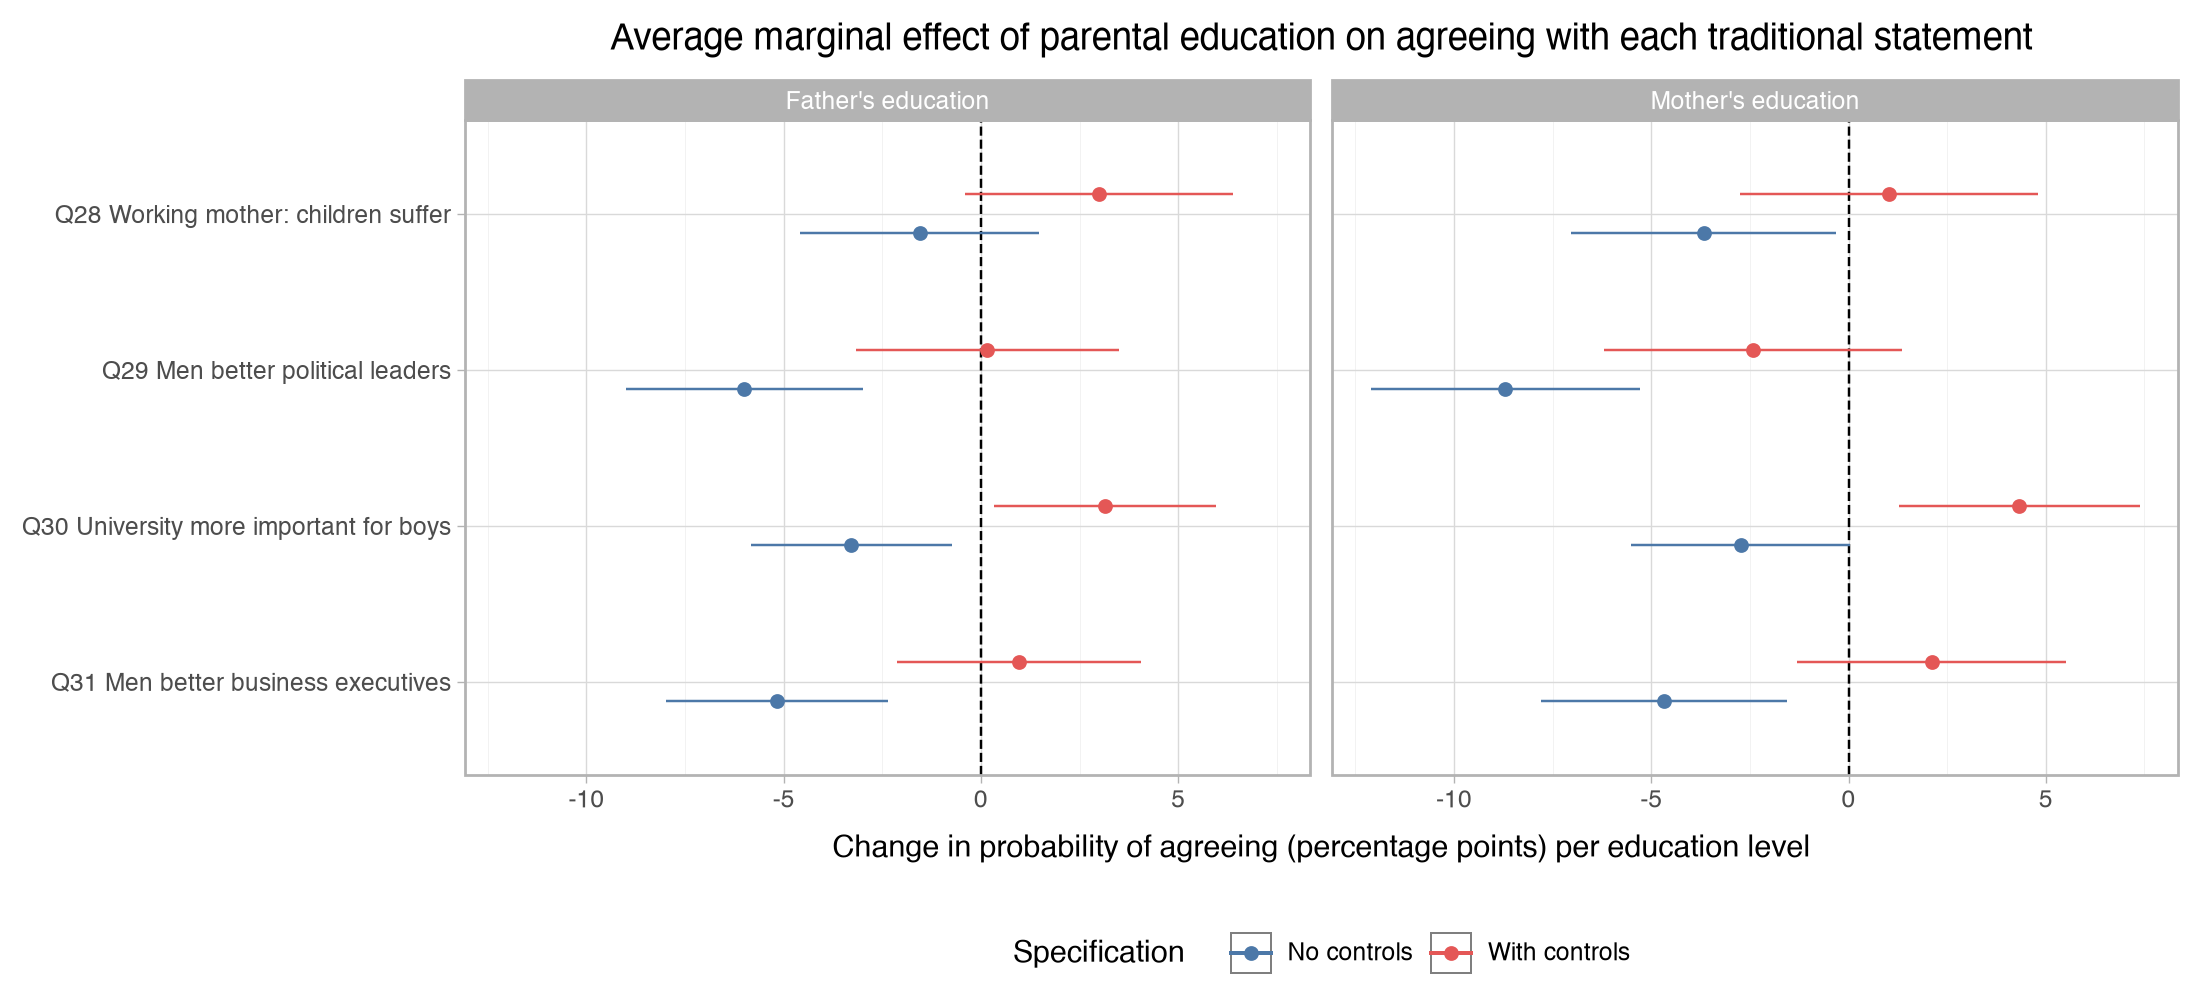

In [8]:
plot_df = item_results.copy()  # copy of the results
for col in ["AME", "AME 2.5%", "AME 97.5%"]:  # convert the AMEs and CIs to percentage points
    plot_df[col] = plot_df[col] * 100  # e.g. -0.05 becomes -5 percentage points
plot_df["Item"] = pd.Categorical(plot_df["Item"], categories=list(items.values())[::-1])  # Q28 at the top

p = (
    ggplot(plot_df, aes(x="Item", y="AME", ymin="AME 2.5%", ymax="AME 97.5%", color="Specification"))  # one point per model
    + geom_hline(yintercept=0, linetype="dashed")  # zero reference line
    + geom_pointrange(position=position_dodge(width=0.5))  # point = AME, line = 95% CI
    + coord_flip()  # horizontal layout, so the item labels are readable
    + facet_wrap("~Parent")  # one panel per parent
    + scale_color_manual(values={"No controls": "#4C78A8", "With controls": "#E45756"})  # colours for the specifications
    + theme_light()  # clean background
    + labs(x="", y="Change in probability of agreeing (percentage points) per education level",  # axis labels
           title="Average marginal effect of parental education on agreeing with each traditional statement")  # title
    + theme(figure_size=(11, 5), legend_position="bottom")  # figure size and legend position
)
p.save(OUTPUT_FIGURES / "item_logit_ames.png", dpi=300, verbose=False)  # save the figure
p  # display the figure

### Interpretation

The plot makes the main pattern easy to see:

- **Without controls (blue)**, all AMEs are negative, and the confidence intervals for **political leadership (Q29)** and **business executives (Q31)** are clearly below zero for both parents. These two "men are better leaders" items are the domains most strongly linked to parental education. **Q28 (working mothers)** has the smallest effects, and its confidence interval for father's education crosses zero.
- **With controls (red)**, all estimates move to the right, towards zero or above it. Most confidence intervals now cross zero. The exception is **Q30**, where the interval lies entirely above zero for both parents.

The overlap between the confidence intervals for different items means we should not over-interpret differences between domains. We fitted **separate** models for each item and never formally tested whether, for example, the Q29 association is significantly larger than the Q28 association. So the most we can say is that these **exploratory analyses suggest** that the associations (without controls) were stronger for the **public-leadership** items (Q29 and Q31) than for **mothers' employment** (Q28).

## 7. Sensitivity Check: Parental Education as Categories

The descriptive table in Section 3 showed that the pattern is not a smooth straight line. For example, agreement with Q28 is 36.0% → 38.4% → 23.7% across mother's education levels. A single "per education level" coefficient may therefore summarise the pattern poorly. We refit every model with parental education as a **category**, so that Middle and Higher are each compared with Lower, and report:

- the **AME** for Middle vs. Lower and for Higher vs. Lower (in percentage points), from `avg_comparisons`;
- a **likelihood-ratio test** of both parental education categories together, comparing the model with and without them (the logit version of the F-test for nested models).

`marginaleffects` needs the categorical variable to be stored as a pandas `Categorical`, so we create one first.

In [9]:
from scipy import stats  # chi-squared distribution for the likelihood-ratio test

cat_rows = []  # list to collect the results
for item, iname in items.items():  # loop over the four items
    for parent, pname in parents.items():  # loop over mother and father
        for spec, extra in [("No controls", []), ("With controls", controls)]:  # the two specifications
            data = df.dropna(subset=[f"agree_{item}", parent] + controls).copy()  # same respondents as Section 5
            data["edu_cat"] = pd.Categorical(data[parent].map(edu_labels), ["Lower", "Middle", "Higher"])  # categorical education
            rhs = " + ".join(extra) if extra else "1"  # right-hand side without parental education
            full = smf.logit(f"agree_{item} ~ C(edu_cat) + {rhs}", data=data).fit(disp=0)  # with parental education categories
            reduced = smf.logit(f"agree_{item} ~ {rhs}", data=data).fit(disp=0)  # without parental education
            lr_p = stats.chi2.sf(2 * (full.llf - reduced.llf), 2)  # likelihood-ratio test, 2 degrees of freedom
            ame = avg_comparisons(full, variables="edu_cat").to_pandas()  # AMEs: Middle - Lower and Higher - Lower
            row = {"Item": iname, "Parent": pname, "Specification": spec, "N": int(full.nobs), "LR test p": lr_p}
            for _, r in ame.iterrows():  # one row per contrast
                level = "Middle" if r["contrast"].startswith("Middle") else "Higher"  # which contrast this is
                row[f"AME {level} vs Lower (pp)"] = r["estimate"] * 100  # AME in percentage points
                row[f"p {level} vs Lower"] = r["p_value"]  # its p-value
            cat_rows.append(row)

item_categorical = pd.DataFrame(cat_rows)  # combine into one table
item_categorical.to_csv(OUTPUT_TABLES / "item_logit_categorical.csv", index=False)  # save the table
item_categorical.round(4)  # display the table

,Item,Parent,Specification,N,LR test p,AME Middle vs Lower (pp),p Middle vs Lower,AME Higher vs Lower (pp),p Higher vs Lower
0,Q28 Working mother: children suffer,Mother's education,No controls,1878,0.0015,2.3602,0.3930,-12.2774,0.0004
1,Q28 Working mother: children suffer,Mother's education,With controls,1878,0.0012,9.4532,0.0020,-4.1783,0.3095
2,Q28 Working mother: children suffer,Father's education,No controls,1820,0.2170,1.4971,0.5745,-4.8307,0.1333
3,Q28 Working mother: children suffer,Father's education,With controls,1820,0.0282,7.5936,0.0078,3.7040,0.3163
4,Q29 Men better political leaders,Mother's education,No controls,1863,0.0000,-8.0329,0.0017,-16.1893,0.0000
5,Q29 Men better political leaders,Mother's education,With controls,1863,0.2453,-0.0361,0.9902,-6.7072,0.0944
6,Q29 Men better political leaders,Father's education,No controls,1805,0.0004,-6.1224,0.0157,-11.3503,0.0001
7,Q29 Men better political leaders,Father's education,With controls,1805,0.7435,1.7957,0.5128,-0.6027,0.8669
8,Q30 University more important for boys,Mother's education,No controls,1877,0.0082,1.0973,0.6215,-8.3105,0.0007
9,Q30 University more important for boys,Mother's education,With controls,1877,0.0000,12.2777,0.0000,2.8340,0.4612


### Interpretation

**Without controls**, the categories confirm that the association comes mostly from the **Higher** group. For example, respondents whose mother had higher education are **16.2** percentage points less likely to agree with Q29 than those whose mother had lower education (p < .001), while the Middle group is 8.0 points less likely (p = .002). For **Q28**, the Middle group does not differ from Lower (+2.4 pp, p = .39), and only the Higher group is less likely to agree (−12.3 pp, p < .001). This is the "only the highest level matters" pattern from Section 3, which the numeric coefficient could not show.

**With controls**, a different pattern appears that the numeric models hid. For **Q28, Q30 and Q31**, respondents whose **mother had middle education** are *more* likely to agree with the traditional statement than those whose mother had lower education (Q28 +9.5 pp, p = .002; Q30 +12.3 pp, p < .001; Q31 +8.9 pp, p = .002), while the Higher group does not differ from Lower (all p > .30). A similar but weaker pattern appears for father's education on Q28 and Q30.

So the "Q30 reversal" in Section 5 is **not specific to Q30**, and it is driven by the **Middle** category rather than by a steady increase across education levels. The same Middle-group pattern appears for the composite score in `06_multivariate_models.ipynb` (Section 8.4). We do not have an explanation for it. It may reflect the particular (and fairly small) group of respondents whose mothers had middle education but who did not reach higher education themselves. These are again many tests, so this pattern should also be treated as **exploratory**. The main point is methodological: the numeric 1–2–3 coding does not represent the item-level patterns well, especially after controls.

## 8. Sensitivity Check: Ordinal Logit Models (All Four Response Levels)

The binary outcomes throw away the difference between "agree" and "strongly agree" (and between "disagree" and "strongly disagree"). An **ordinal logistic regression** (proportional-odds model) keeps all four response levels. It estimates one coefficient per predictor, describing how the odds of giving a **more traditional** answer change, under the assumption that this change is the same at every cut-point of the scale. This method was not covered in class. We use `OrderedModel` from `statsmodels`, the same library we use for OLS and logit models.

We use the reverse-coded items (`Q28_rev`–`Q31_rev`, 1 = strongly disagree … 4 = strongly agree, so **higher = more traditional**) and fit the same 16 models as in Section 5 (numeric parental education, without and with controls). A **positive** coefficient means higher parental education goes with *more* traditional answers, and a negative one with *less* traditional answers.

In [10]:
from statsmodels.miscmodels.ordinal_model import OrderedModel  # ordinal (proportional-odds) logistic regression

ord_rows = []  # list to collect the results
for item, iname in items.items():  # loop over the four items
    for parent, pname in parents.items():  # loop over mother and father
        for spec, extra in [("No controls", []), ("With controls", controls)]:  # the two specifications
            data = df.dropna(subset=[f"{item}_rev", parent] + controls)  # same respondents for both specifications
            y = data[f"{item}_rev"].astype(int)  # outcome: 1-4, higher = more traditional
            X = data[[parent] + extra]  # predictors (OrderedModel has no separate intercept; the cut-points take its place)
            model = OrderedModel(y, X, distr="logit").fit(method="bfgs", disp=False)  # fit the ordinal logit model
            ord_rows.append({"Item": iname, "Parent": pname, "Specification": spec, "N": int(model.nobs),
                             "Ordinal logit b": model.params[parent], "Odds ratio": np.exp(model.params[parent]),
                             "p-value": model.pvalues[parent]})

item_ordinal = pd.DataFrame(ord_rows)  # combine into one table
item_ordinal["p < .05/16"] = np.where(item_ordinal["p-value"] < 0.05 / 16, "Yes", "No")  # Bonferroni over the 16 models
item_ordinal["Same sign as binary logit"] = np.where(  # does the ordinal result point the same way as Section 5?
    np.sign(item_ordinal["Ordinal logit b"]) == np.sign(item_results["Logit b"]), "Yes", "No")  # both: positive = more traditional
item_ordinal.to_csv(OUTPUT_TABLES / "item_ordinal_logit_results.csv", index=False)  # save the table
item_ordinal.round(4)  # display the table

,Item,Parent,Specification,N,Ordinal logit b,Odds ratio,p-value,p < .05/16,Same sign as binary logit
0,Q28 Working mother: children suffer,Mother's education,No controls,1878,-0.2990,0.7416,0.0000,Yes,Yes
1,Q28 Working mother: children suffer,Mother's education,With controls,1878,-0.0984,0.9063,0.2092,No,No
2,Q28 Working mother: children suffer,Father's education,No controls,1820,-0.2022,0.8170,0.0014,Yes,Yes
3,Q28 Working mother: children suffer,Father's education,With controls,1820,-0.0103,0.9897,0.8846,No,No
4,Q29 Men better political leaders,Mother's education,No controls,1863,-0.4878,0.6140,0.0000,Yes,Yes
5,Q29 Men better political leaders,Mother's education,With controls,1863,-0.1747,0.8397,0.0271,No,Yes
6,Q29 Men better political leaders,Father's education,No controls,1805,-0.4184,0.6581,0.0000,Yes,Yes
7,Q29 Men better political leaders,Father's education,With controls,1805,-0.1224,0.8848,0.0901,No,No
8,Q30 University more important for boys,Mother's education,No controls,1877,-0.4450,0.6409,0.0000,Yes,Yes
9,Q30 University more important for boys,Mother's education,With controls,1877,0.0165,1.0167,0.8332,No,Yes


### Interpretation

**Without controls**, the ordinal models agree with the binary models and are, if anything, clearer. All eight coefficients are negative and pass the Bonferroni threshold (all p ≤ .0014): higher parental education goes with **less** traditional answers on every item. Using all four response levels gives more statistical power. For example, Q28 and Q30 are now clearly significant for both parents, whereas in the binary models some of these results were not. Q28 still has the smallest coefficients (mother b = −0.299, father b = −0.202, compared with −0.39 to −0.49 for the other items), which is again only an exploratory pattern.

**With controls**, none of the eight ordinal coefficients passes the Bonferroni threshold, and only mother's education for Q29 is significant at .05 without correction (b = −0.175, p = .027). Most importantly, the **Q30 "reversal" disappears**: mother b = +0.017 (p = .83), father b = +0.047 (p = .51). The positive binary result for Q30 therefore seems to depend on how the four response levels were collapsed into agree/disagree, and it is **not robust** to this specification check.

The proportional-odds model assumes that parental education shifts the odds in the same way at every cut-point of the scale. We did not test this assumption, so these models are a sensitivity check rather than our main item-level results.

## Summary

*All results in this notebook are exploratory.*

- **Agreement with traditional statements** is highest for working mothers (Q28, 35.3%) and lowest for university education (Q30, 17.5%).
- **Without controls**, the associations with parental education were largest for the **public-leadership** items: **political leaders** (Q29: −8.7 percentage points per level of mother's education, −6.0 for father's) and **business executives** (Q31: about −5 pp). They were smallest for **working mothers** (Q28: −3.7 pp for mothers, not significant for fathers). We did not formally test whether these item-level differences are significant, so this pattern is only suggestive. It is consistent with the PCA finding that Q28 behaves somewhat differently.
- **Multiple testing:** after a Bonferroni correction over the 16 models (p < .0031), only the Q29 results and the father's Q31 result remain significant.
- **With controls** for sex, age and own education, the numeric associations with Q28, Q29 and Q31 are no longer significant. For **Q30**, the binary association appears to reverse (+3 to +4 pp), but this apparent reversal was **not consistently robust to correction for multiple testing** and disappears in the ordinal models, so we do not interpret it substantively.
- **Categorical parental education:** the numeric coding hides non-linear patterns. Without controls, the associations come mainly from the Higher group. With controls, the Middle mother-education group is *more* likely to agree with Q28, Q30 and Q31 than the Lower group, so the "Q30 reversal" is neither specific to Q30 nor a steady trend.
- **Ordinal logit (all four response levels):** without controls, all eight associations are negative and survive the Bonferroni correction. With controls, none does, and the **Q30 reversal disappears** (p = .83 and .51), so it is not robust to this specification check.
- **Overall:** these exploratory analyses suggest that the association between parental education and the composite score is stronger for attitudes about **women in public leadership roles** than for attitudes about **mothers' employment and childcare**. As with the composite, the associations are largely attenuated after adjusting for sex, age and own education. Own education may lie on the pathway between parental education and attitudes (a mediator), so this attenuation does not show that the associations are accounted for by age/cohort or own education.

**Limitations:**
- Turning 4-point items into yes/no outcomes loses information (e.g. "agree" vs. "strongly agree"). The ordinal models in Section 8 keep this information, but rely on the untested proportional-odds assumption.
- Mother's and father's education are tested in separate models despite being strongly correlated, so the results are not clean parent-specific effects.
- The main models treat parental education as a numeric score. The categorical check (Section 7) shows that this does not capture the patterns well.
- Many tests were run (16 main models, 16 categorical models and 16 ordinal models), so some significant results could be due to chance. We use Bonferroni corrections and treat the whole notebook as exploratory.
- Differences between items were not formally tested.
- The data is cross-sectional and unweighted, each model uses complete cases only, and parental education is self-reported.